In [2408]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("Libraries imported successfully!")

Libraries imported successfully!


In [2409]:
# Load the Iris dataset
iris = load_iris()

# Convert dataset into a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df["target"] = iris.target

# Add flower species names
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

# Display first five rows
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  


In [2410]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Dataset Shape: (150, 6)
Number of Rows: 150
Number of Columns: 6


In [2411]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [2412]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


In [2413]:
# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 1


In [2414]:
# Statistical summary
print(df.describe())

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  


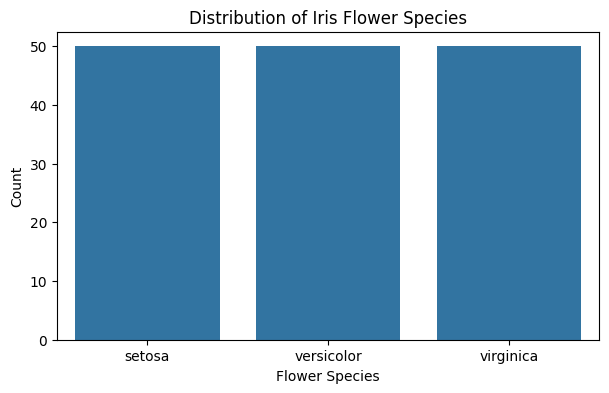

In [2415]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Count")

plt.show()

In [2416]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check duplicates again
print("Duplicates after removal:", df.duplicated().sum())

# Check updated dataset shape
print("Updated Dataset Shape:", df.shape)

Duplicates after removal: 0
Updated Dataset Shape: (149, 6)


In [2417]:
# Input features
X = df[iris.feature_names]

# Output target
y = df["target"]

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (149, 4)
Output Shape: (149,)


In [2418]:
from sklearn.model_selection import train_test_split

In [2419]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (119, 4)
Testing data: (30, 4)


In [2420]:
from sklearn.preprocessing import StandardScaler

In [2421]:
# Create StandardScaler object
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [2422]:
print("Original Training Data:")
print(X_train.head())

print("\nScaled Training Data:")
print(X_train_scaled[:5])

Original Training Data:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
6                  4.6               3.4                1.4               0.3
128                6.4               2.8                5.6               2.1
95                 5.7               3.0                4.2               1.2
44                 5.1               3.8                1.9               0.4
30                 4.8               3.1                1.6               0.2

Scaled Training Data:
[[-1.50158712  0.7690314  -1.33909259 -1.17973677]
 [ 0.63982407 -0.58674247  1.04183404  1.1863645 ]
 [-0.19294695 -0.13481785  0.24819183  0.00331387]
 [-0.90675068  1.67288064 -1.05564894 -1.0482867 ]
 [-1.26365254  0.09114446 -1.22571513 -1.31118684]]


In [2423]:
from sklearn.linear_model import LogisticRegression

In [2424]:
# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [2425]:
# Predict using test data
lr_predictions = lr_model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(lr_predictions)

Actual Values:
[1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 1 0 2 0 1 2 0 0 1 1 2 2 2 1]

Predicted Values:
[1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 2 0 2 0 1 1 0 0 1 1 2 2 2 1]


In [2426]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %


In [2427]:
from sklearn.tree import DecisionTreeClassifier

In [2428]:
# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [2429]:
# Predict using testing data
dt_predictions = dt_model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(dt_predictions)

Actual Values:
[1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 1 0 2 0 1 2 0 0 1 1 2 2 2 1]

Predicted Values:
[1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 2 0 2 0 1 1 0 0 1 1 2 2 2 1]


In [2430]:
dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 93.33333333333333 %


In [2431]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": lr_predictions,
    "Decision Tree": dt_predictions
}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, average="macro"
    )

    recall = recall_score(
        y_test, predictions, average="macro"
    )

    f1 = f1_score(
        y_test, predictions, average="macro"
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.933333   0.933333  0.933333  0.933333
1        Decision Tree  0.933333   0.933333  0.933333  0.933333


In [2432]:
from sklearn.metrics import classification_report

In [2433]:
print("LOGISTIC REGRESSION REPORT")

print(classification_report(
    y_test,
    lr_predictions,
    target_names=iris.target_names
))

print("DECISION TREE REPORT")

print(classification_report(
    y_test,
    dt_predictions,
    target_names=iris.target_names
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

DECISION TREE REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [2434]:
from sklearn.metrics import confusion_matrix

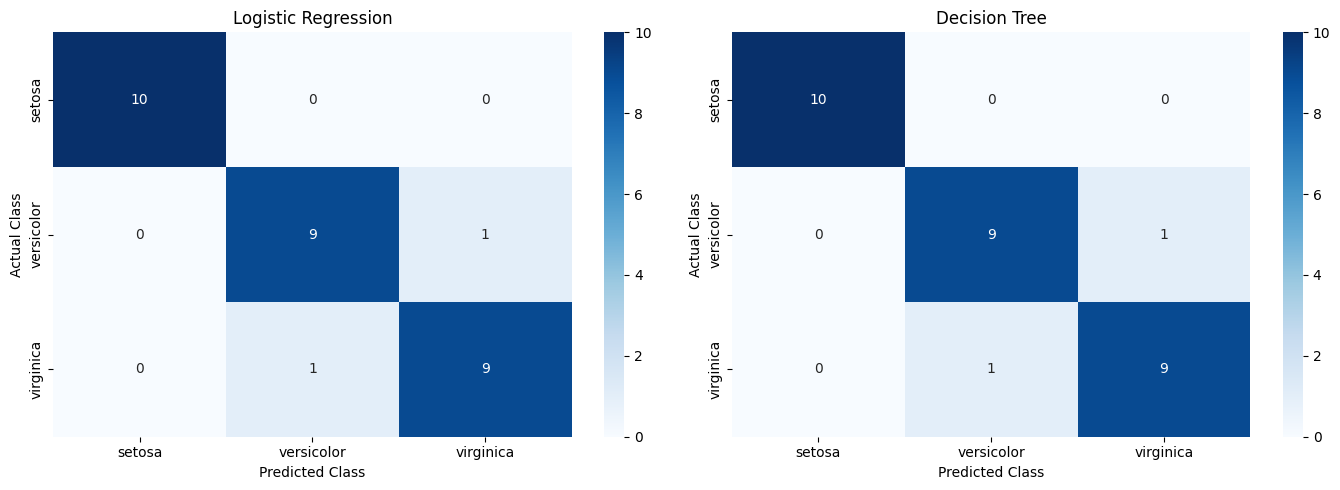

In [2435]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = {
    "Logistic Regression": lr_predictions,
    "Decision Tree": dt_predictions
}

for ax, (name, predictions) in zip(axes, models.items()):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [2436]:
from sklearn.decomposition import PCA

In [2437]:
# Apply PCA to training data
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)

print("PCA Transformation Completed!")
print("New Training Shape:", X_train_pca.shape)

PCA Transformation Completed!
New Training Shape: (119, 2)


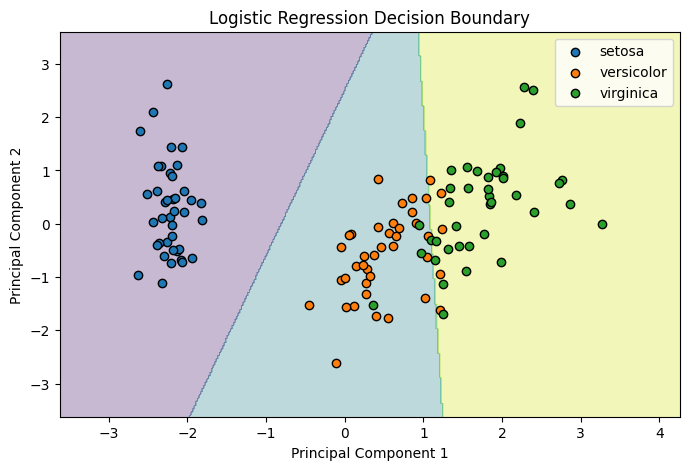

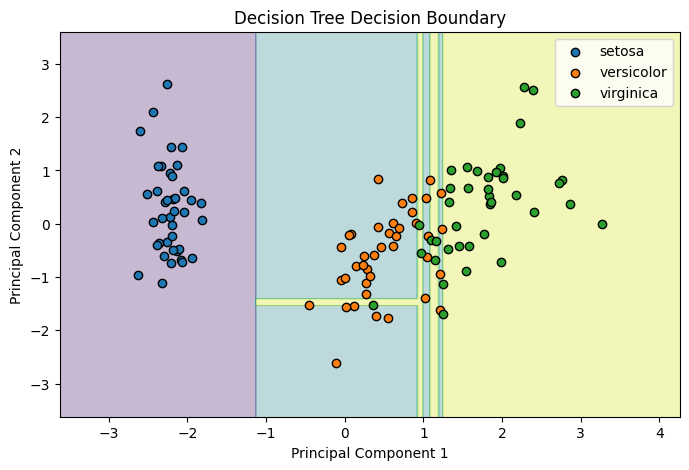

In [2438]:
# Create visualization models
visual_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

# Define colors
colors = ["red", "green", "blue"]

for name, model in visual_models.items():

    # Train model using PCA data
    model.fit(X_train_pca, y_train)

    # Create mesh grid
    x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
    y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    # Predict mesh points
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot decision boundary
    plt.figure(figsize=(8, 5))

    plt.contourf(
        xx, yy, Z,
        alpha=0.3,
        cmap="viridis"
    )

    # Plot training samples
    for i, species in enumerate(iris.target_names):
        plt.scatter(
            X_train_pca[y_train == i, 0],
            X_train_pca[y_train == i, 1],
            label=species,
            edgecolor="black"
        )

    plt.title(name + " Decision Boundary")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.legend()
    plt.show()

In [2439]:
import pandas as pd
from sklearn.datasets import load_iris

# Load Iris data
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=[
        'sepal_length',
        'sepal_width',
        'petal_length',
        'petal_width'
    ]
)

# Add species names
df['species'] = [iris.target_names[i] for i in iris.target]

# Save as CSV
df.to_csv('iris.csv', index=False)

print("Dataset created successfully!")
print(df.head())

Dataset created successfully!
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [2440]:
# Display first 5 rows
print(df.head())

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column information
print(df.info())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
Dataset Shape: (150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate

In [2441]:
# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check missing values again
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# Display cleaned dataset
print("\nCleaned Dataset:")
print(df.head())

print("\nFinal Dataset Shape:", df.shape)

Missing values before cleaning:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Missing values after cleaning:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Cleaned Dataset:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Final Dataset Shape: (149, 5)


In [2442]:
# Separate input features
X = df.drop('species', axis=1)

# Separate target variable
y = df['species']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target Variable:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object

Input Shape: (149, 4)
Target Shape: (149,)


In [2443]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (119, 4)
Testing data: (30, 4)
Training labels: (119,)
Testing labels: (30,)


In [2444]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create the model
lr_model = LogisticRegression(max_iter=200)

# Train the model
lr_model.fit(X_train, y_train)

# Predict test data
y_pred_lr = lr_model.predict(X_test)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:",
      lr_accuracy * 100, "%")

Logistic Regression Accuracy: 96.66666666666667 %


In [2445]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create the model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Predict test data
y_pred_dt = dt_model.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:",
      dt_accuracy * 100, "%")

Decision Tree Accuracy: 93.33333333333333 %


In [2446]:
import pandas as pd

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [
        lr_accuracy * 100,
        dt_accuracy * 100
    ]
})

print(results)

                 Model   Accuracy
0  Logistic Regression  96.666667
1        Decision Tree  93.333333


In [2447]:
from sklearn.metrics import classification_report

print("Logistic Regression Report:")
print(classification_report(y_test, y_pred_lr))

print("Decision Tree Report:")
print(classification_report(y_test, y_pred_dt))

Logistic Regression Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Decision Tree Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [2448]:
from sklearn.metrics import classification_report

print("Logistic Regression Report:")
print(classification_report(y_test, y_pred_lr))

print("Decision Tree Report:")
print(classification_report(y_test, y_pred_dt))

Logistic Regression Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Decision Tree Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



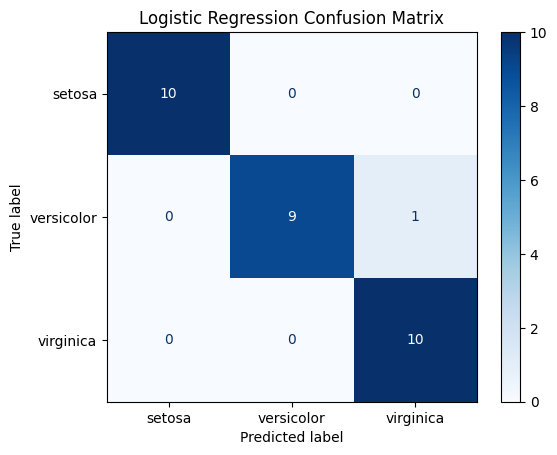

In [2449]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=lr_model.classes_
)

disp.plot(cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [2450]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Decision Tree Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [2451]:
results.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


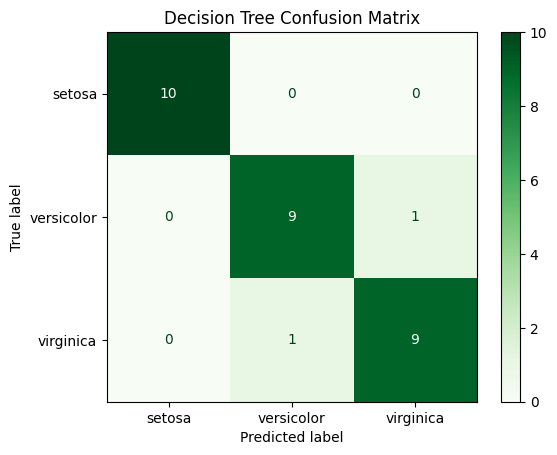

In [2452]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=dt_model.classes_
)

disp.plot(cmap='Greens')
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [2453]:
import joblib

# Save Logistic Regression model
joblib.dump(lr_model, 'logistic_regression.pkl')

# Save Decision Tree model
joblib.dump(dt_model, 'decision_tree.pkl')

print("Both models saved successfully!")

Both models saved successfully!


In [2454]:
from google.colab import files

files.download('logistic_regression.pkl')
files.download('decision_tree.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2455]:
from sklearn.preprocessing import StandardScaler

# Create StandardScaler
scaler = StandardScaler()

# Scale training data
X_train_scaled = scaler.fit_transform(X_train)

# Scale testing data
X_test_scaled = scaler.transform(X_test)

print("Training data scaled successfully!")
print("Testing data scaled successfully!")

print("Training Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

Training data scaled successfully!
Testing data scaled successfully!
Training Shape: (119, 4)
Testing Shape: (30, 4)


In [2456]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create Logistic Regression model
lr_model_scaled = LogisticRegression(max_iter=200)

# Train using scaled data
lr_model_scaled.fit(X_train_scaled, y_train)

# Make predictions
y_pred_lr_scaled = lr_model_scaled.predict(X_test_scaled)

# Calculate accuracy
lr_scaled_accuracy = accuracy_score(
    y_test, y_pred_lr_scaled
)

print("Scaled Logistic Regression Accuracy:",
      lr_scaled_accuracy * 100, "%")

Scaled Logistic Regression Accuracy: 93.33333333333333 %


In [2457]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create Decision Tree model
dt_model_scaled = DecisionTreeClassifier(random_state=42)

# Train using scaled data
dt_model_scaled.fit(X_train_scaled, y_train)

# Make predictions
y_pred_dt_scaled = dt_model_scaled.predict(X_test_scaled)

# Calculate accuracy
dt_scaled_accuracy = accuracy_score(
    y_test, y_pred_dt_scaled
)

print("Scaled Decision Tree Accuracy:",
      dt_scaled_accuracy * 100, "%")

Scaled Decision Tree Accuracy: 93.33333333333333 %


In [2458]:
import pandas as pd

scaled_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [
        lr_scaled_accuracy * 100,
        dt_scaled_accuracy * 100
    ]
})

print(scaled_results)

                 Model   Accuracy
0  Logistic Regression  93.333333
1        Decision Tree  93.333333


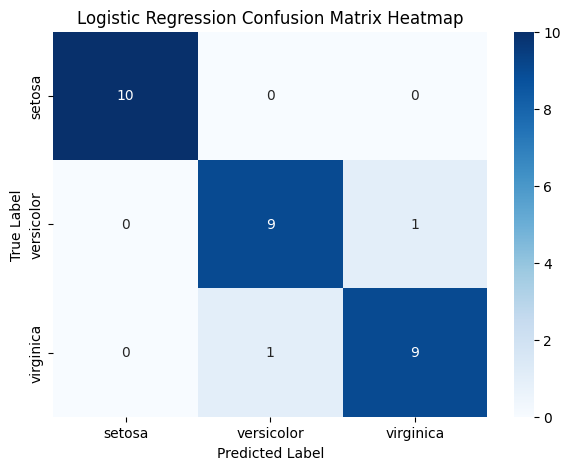

In [2459]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr_scaled)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=lr_model_scaled.classes_,
    yticklabels=lr_model_scaled.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Logistic Regression Confusion Matrix Heatmap")
plt.show()

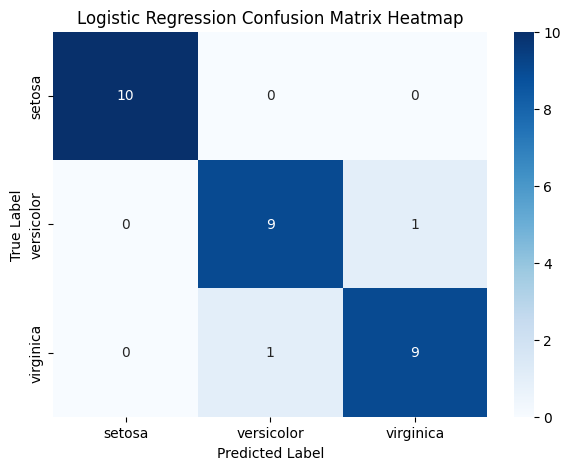

In [2460]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_lr_scaled)

# Plot heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=lr_model_scaled.classes_,
    yticklabels=lr_model_scaled.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Logistic Regression Confusion Matrix Heatmap")

plt.show()

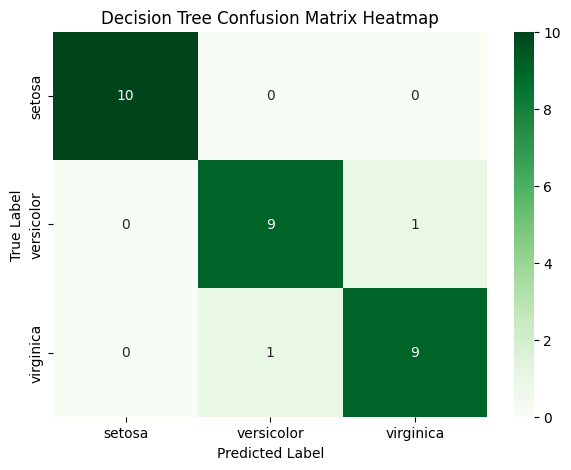

In [2461]:
cm_dt = confusion_matrix(y_test, y_pred_dt_scaled)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=dt_model_scaled.classes_,
    yticklabels=dt_model_scaled.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Decision Tree Confusion Matrix Heatmap")

plt.show()

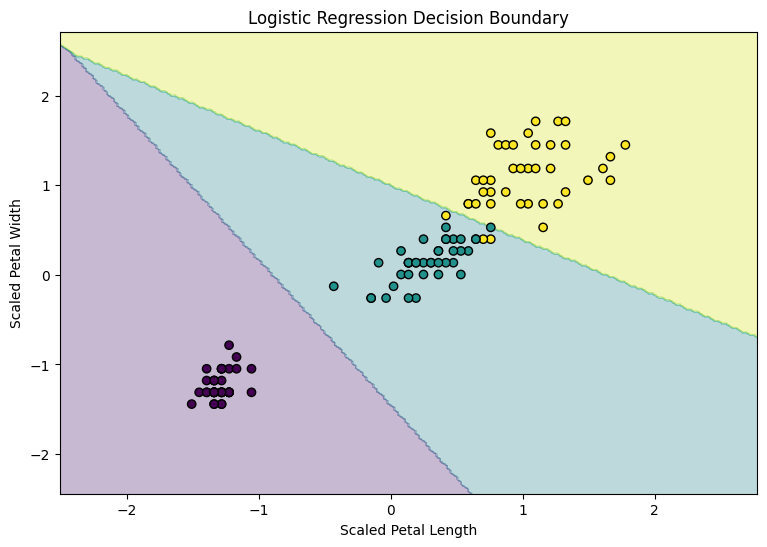

In [2462]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# Select two features
X_2d = df[['petal_length', 'petal_width']]
y_2d = df['species']

# Split dataset
from sklearn.model_selection import train_test_split

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

# Scale features
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

# Train Logistic Regression
boundary_model = LogisticRegression(max_iter=200)
boundary_model.fit(X_train_2d_scaled, y_train_2d)

# Create mesh grid
x_min, x_max = X_train_2d_scaled[:, 0].min() - 1, X_train_2d_scaled[:, 0].max() + 1
y_min, y_max = X_train_2d_scaled[:, 1].min() - 1, X_train_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# Predict regions
Z = boundary_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = LabelEncoder().fit(y_2d).transform(Z)
Z = Z.reshape(xx.shape)

# Plot decision boundaries
plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

plt.scatter(
    X_train_2d_scaled[:, 0],
    X_train_2d_scaled[:, 1],
    c=LabelEncoder().fit(y_2d).transform(y_train_2d),
    cmap='viridis',
    edgecolors='black'
)

plt.xlabel("Scaled Petal Length")
plt.ylabel("Scaled Petal Width")
plt.title("Logistic Regression Decision Boundary")
plt.show()

In [2463]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))

print("Decision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Decision Tree Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



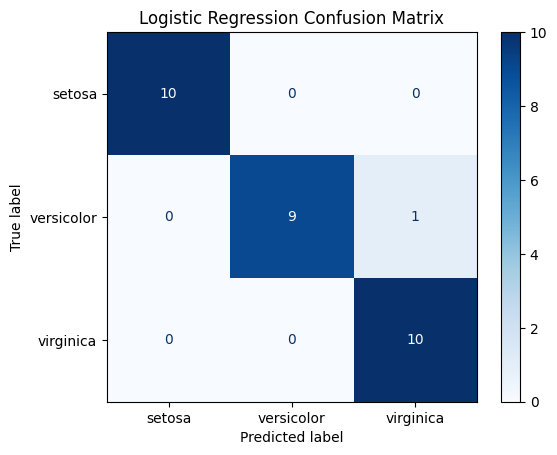

In [2464]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Logistic Regression Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=iris.target_names
)

disp.plot(cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.show()

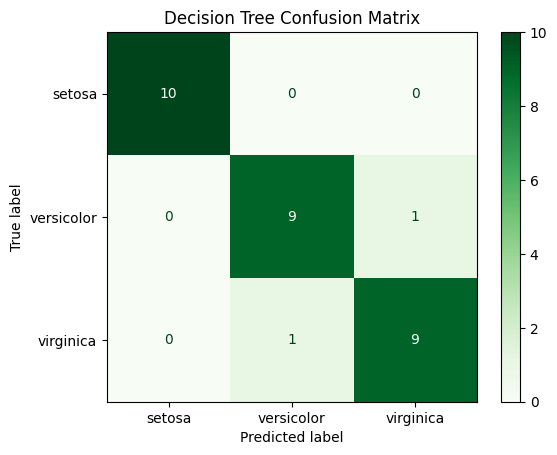

In [2465]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Decision Tree Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=iris.target_names
)

disp.plot(cmap='Greens')
plt.title("Decision Tree Confusion Matrix")
plt.show()

Logistic Regression Accuracy: 96.66666666666667 %
Decision Tree Accuracy: 93.33333333333333 %


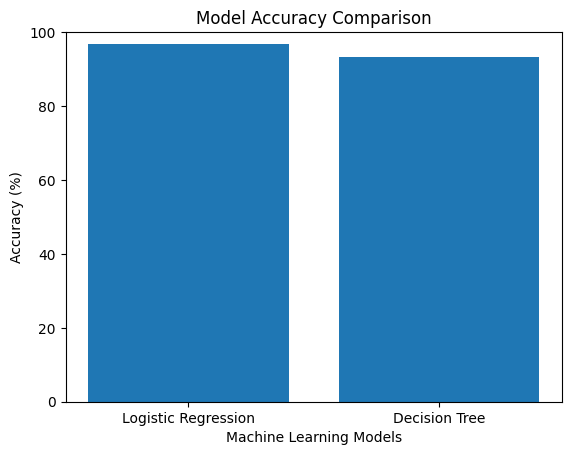

In [2466]:
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)
dt_accuracy = accuracy_score(y_test, y_pred_dt)

# Display accuracy
print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")
print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

# Plot comparison
models = ['Logistic Regression', 'Decision Tree']
accuracies = [lr_accuracy * 100, dt_accuracy * 100]

plt.bar(models, accuracies)
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 100)
plt.show()

In [2467]:
import joblib

# Save Logistic Regression model
joblib.dump(lr_model, 'iris_logistic_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [2468]:
import joblib

# Load the saved model
loaded_model = joblib.load('iris_logistic_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


In [2469]:
import pandas as pd

# Get the exact column names used during training
feature_columns = scaler.feature_names_in_

# Create new flower data
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=feature_columns
)

# Scale the new data
new_flower_scaled = scaler.transform(new_flower)

# Predict using the loaded model
prediction = loaded_model.predict(new_flower_scaled)

# Display result
print("Predicted Iris Species:", prediction[0])

Predicted Iris Species: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [2470]:
import pandas as pd

# Create new flower data
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=scaler.feature_names_in_
)

# Scale input
new_flower_scaled = scaler.transform(new_flower)

# Convert scaled data back to DataFrame
new_flower_scaled_df = pd.DataFrame(
    new_flower_scaled,
    columns=scaler.feature_names_in_
)

# Predict
prediction = loaded_model.predict(new_flower_scaled_df)

print("Predicted Iris Species:", prediction[0])

Predicted Iris Species: setosa


In [2471]:
import pandas as pd

# Three new flower samples
new_flowers = pd.DataFrame(
    [
        [5.1, 3.5, 1.4, 0.2],
        [6.0, 2.9, 4.5, 1.5],
        [6.5, 3.0, 5.5, 2.0]
    ],
    columns=scaler.feature_names_in_
)

# Scale the input data
scaled_flowers = scaler.transform(new_flowers)

# Convert scaled data into DataFrame
scaled_flowers_df = pd.DataFrame(
    scaled_flowers,
    columns=scaler.feature_names_in_
)

# Predict flower species
predictions = loaded_model.predict(scaled_flowers_df)

# Display predictions
for i, prediction in enumerate(predictions):
    print(f"Flower {i+1}: {prediction}")

Flower 1: setosa
Flower 2: setosa
Flower 3: setosa


In [2472]:
import joblib

# Save model and scaler together
model_data = {
    'model': loaded_model,
    'scaler': scaler
}

joblib.dump(model_data, 'iris_complete_model.pkl')

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [2473]:
# Load saved model data
loaded_data = joblib.load('iris_complete_model.pkl')

# Extract model and scaler
final_model = loaded_data['model']
final_scaler = loaded_data['scaler']

print("Model and scaler loaded successfully!")

Model and scaler loaded successfully!


In [2474]:
from google.colab import files

files.download('iris_complete_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>